<Axes: >

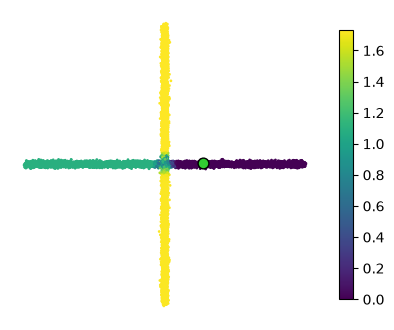

In [29]:
import CovBIM as cb

# cloud = cb.datasets.make("sphere_plane", n_points=15000, noise=0.01, seed=0)
cloud = cb.datasets.make("crossing_lines", n_points=20000, noise=0.01, seed=0)
cfg = cb.PipelineConfig.from_dict({"covariance": {"kernel": "dumb", "k": 1000}, "metric": {"lam": 10, "alpha": 2.0, "beta": 3.0, "spd_metric": "log_euclidean"}, "graph": {"k": 1000}})

# cb.viz.plot_field(cloud.points, values=cloud.labels)

gm = cb.GeodesicMetric(cfg).fit(cloud.points)
d = gm.distances_from(source=0)
# check if converged
if not gm.tyler_.converged.all():
    frac = 1.0 - gm.tyler_.converged.mean()
    print(f"Tyler iterations did not converge at {100 * frac:.1f}% of the points")
    it = gm.tyler_.iterations.max()
    print(f"Maximum iterations: {it}")

d_euc = cb.baselines.BASELINES["euclidean"](cloud.points, 0, k=15)
cb.viz.plot_distance_field(cloud.points, d, source=0)

# with polyscope
# cb.viz.show_polyscope(cloud.points, values=d)

# mesh = cb.datasets.load_file("bunny.obj", n_points=5000)    # any mesh trimesh can read